In [1]:
import pandas as pd
import numpy as np
import seaborn as sna
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import plot_tree,DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV

In [4]:
df_admit=pd.read_csv('C:/Users/hp/OneDrive/Documents/Python/admit.csv')

In [45]:
x=df_admit.drop('Admit',axis=1)
y=df_admit['Admit']

xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.20,random_state=1)

In [35]:
xtrain.shape,ytrain.shape

((320, 7), (320,))

In [36]:
ytest.shape,ytest.shape

((80,), (80,))

In [47]:
raw_model_logistic=LogisticRegression().fit(xtrain,ytrain)
raw_model_DT=DecisionTreeClassifier().fit(xtrain,ytrain)

C:\Users\hp\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [48]:
predicted_logistic=raw_model_logistic.predict(xtest)
predicted_DT=raw_model_DT.predict(xtest)

In [39]:
from sklearn.metrics import accuracy_score,classification_report

In [49]:
print('Accuracy of raw logistic model without tuning:',accuracy_score(ytest,predicted_logistic))
print('Accuracy of raw DT model without tuning:',accuracy_score(ytest,predicted_DT)) 

#raw model is done 

Accuracy of raw logistic model without tuning: 0.8125
Accuracy of raw DT model without tuning: 0.775


In [50]:
train_predict_log_model=raw_model_logistic.predict(xtrain)
train_predict_dt_model=raw_model_DT.predict(xtrain)

In [51]:
print('Train Accuracy of raw logistic model without tuning:',accuracy_score(ytrain,train_predict_log_model))
print('Train Accuracy of raw DT model without tuning:',accuracy_score(ytrain,train_predict_dt_model)) 

Train Accuracy of raw logistic model without tuning: 0.803125
Train Accuracy of raw DT model without tuning: 1.0


In [52]:
# Overfit Analysis of Logistic Regrerssion

print('Train Accuracy:', accuracy_score(ytrain,train_predict_log_model))
print('Test Accuracy:', accuracy_score(ytest,predicted_logistic))

Train Accuracy: 0.803125
Test Accuracy: 0.8125


In [53]:
# Overfit Analysis of DT

print('Train Accuracy:', accuracy_score(ytrain,train_predict_dt_model))
print('Test Accuracy:', accuracy_score(ytest,predicted_DT))

Train Accuracy: 1.0
Test Accuracy: 0.775


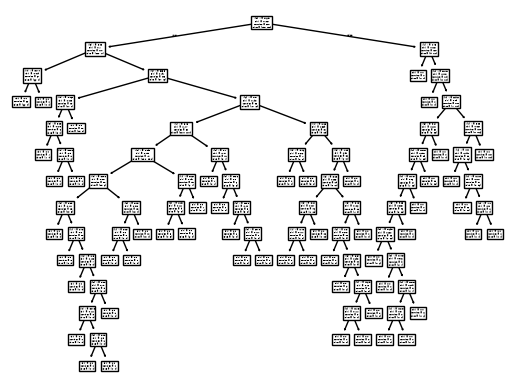

In [44]:
plot_tree(raw_model_DT)
plt.show()

In [57]:
# max depth

max_depth_list=[1,2,3,4,5,6,7,8,9,10,11,12,13]
train_acc=[]
test_acc=[]

for i in max_depth_list:
    dt_model=DecisionTreeClassifier(max_depth=i).fit(xtrain,ytrain)
    train_pred=dt_model.predict(xtrain)
    test_pred=dt_model.predict(xtest)

    train_acc.append(accuracy_score(ytrain,train_pred))
    test_acc.append(accuracy_score(ytest,test_pred))

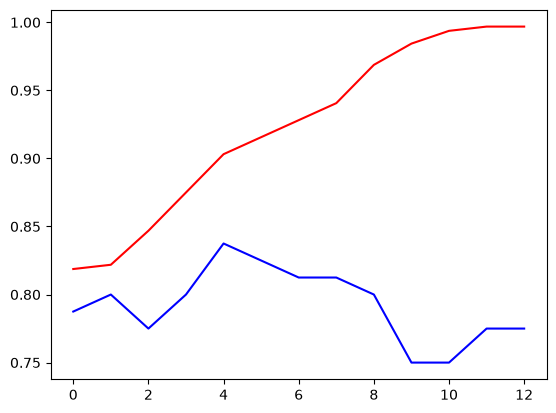

In [58]:
plt.plot(train_acc,color='red')
plt.plot(test_acc,color='blue')


In [59]:
max_df=pd.DataFrame()
max_df['max_depth_values']=max_depth_list
max_df['train_accuracy']=train_acc
max_df['test_accuracy']=test_acc

In [63]:
max_df['generalzation_gap']=max_df['train_accuracy']-max_df['test_accuracy']
max_df.sort_values(by = 'generalzation_gap',ascending=True)

,max_depth_values,train_accuracy,test_accuracy,generalzation_gap
1,2,0.821875,0.8000,0.021875
0,1,0.818750,0.7875,0.031250
4,5,0.903125,0.8375,0.065625
2,3,0.846875,0.7750,0.071875
3,4,0.875000,0.8000,0.075000
5,6,0.915625,0.8250,0.090625
6,7,0.928125,0.8125,0.115625
7,8,0.940625,0.8125,0.128125
8,9,0.968750,0.8000,0.168750
11,12,0.996875,0.7750,0.221875


In [64]:
raw_model_DT.feature_importances_

array([0.11150435, 0.05630518, 0.01370666, 0.03062419, 0.10473145,
       0.65000986, 0.03311831])

In [65]:
feature_imp=pd.DataFrame()
feature_imp['Feature Name']=x.columns
feature_imp['Importance Score']=raw_model_DT.feature_importances_

In [66]:
feature_imp

,Feature Name,Importance Score
0,GRE,0.111504
1,TOEFL,0.056305
2,Univ_Rating,0.013707
3,SOP,0.030624
4,LOR,0.104731
5,CGPA,0.650010
6,Research,0.033118


In [67]:
final_pre_prunning_model=DecisionTreeClassifier(max_depth=2).fit(xtrain,ytrain)

In [68]:
ccp_alpha=raw_model_DT.cost_complexity_pruning_path(xtrain,ytrain)

In [69]:
ccp_alpha #different ccp_alphas. ccp_alphas, impurities are keys->dictionary

{'ccp_alphas': array([0.        , 0.00205177, 0.00234375, 0.00245652, 0.0025    ,
        0.0025    , 0.00260417, 0.00270833, 0.00273437, 0.00290179,
        0.00333203, 0.00333333, 0.00333333, 0.00362103, 0.00384615,
        0.00412281, 0.00454861, 0.00464912, 0.00475799, 0.00553057,
        0.00565476, 0.00597156, 0.01102227, 0.01215402, 0.0203342 ,
        0.04350248, 0.20934289]),
 'impurities': array([0.        , 0.0061553 , 0.0108428 , 0.02312541, 0.02812541,
        0.03312541, 0.03833375, 0.04916708, 0.06010458, 0.06590815,
        0.07923627, 0.08256961, 0.08590294, 0.09676603, 0.10061219,
        0.12122622, 0.13487206, 0.1441703 , 0.14892829, 0.17105056,
        0.18236009, 0.18833165, 0.19935392, 0.21150794, 0.23184213,
        0.27534461, 0.4846875 ])}

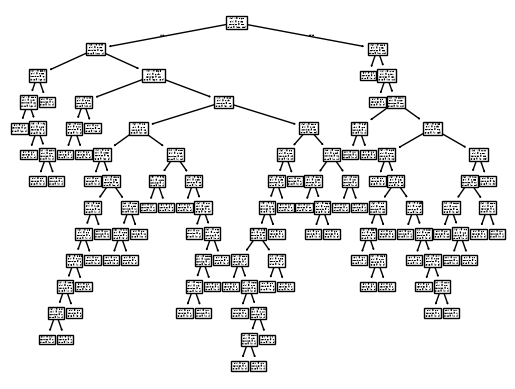

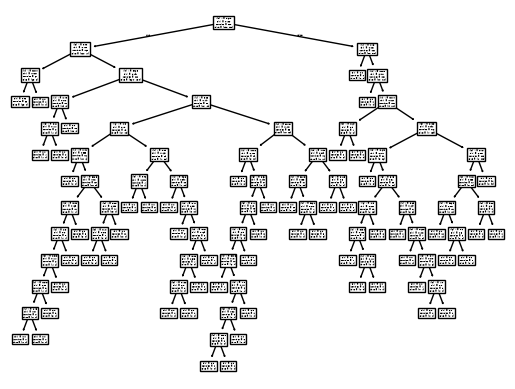

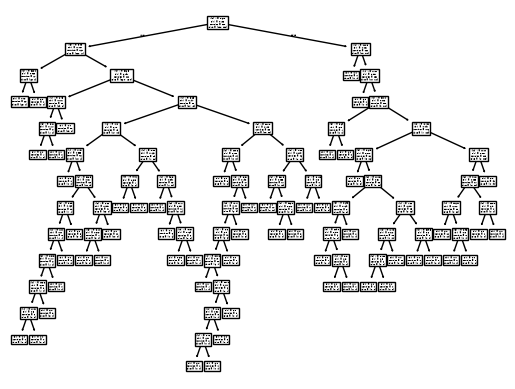

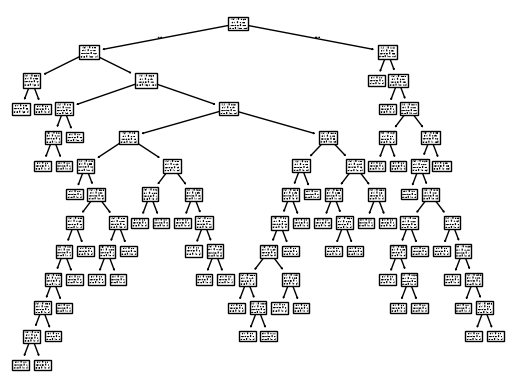

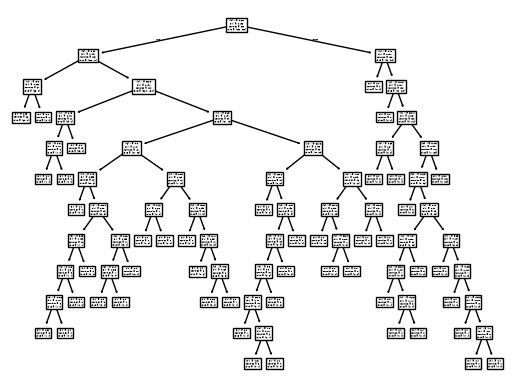

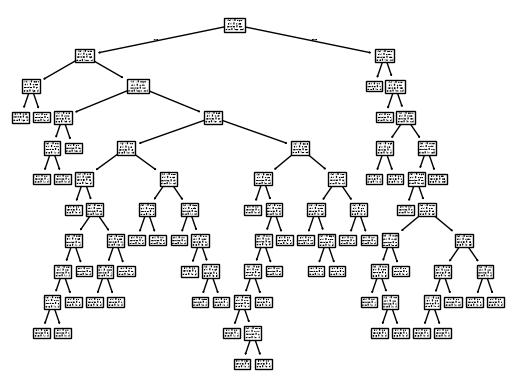

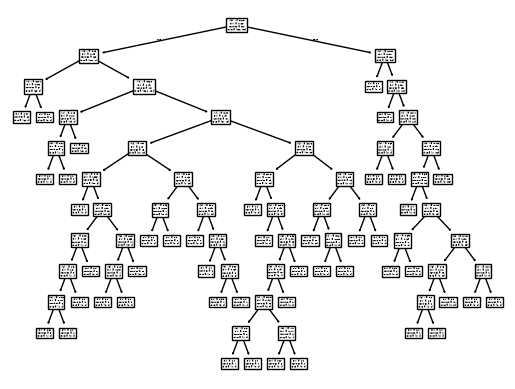

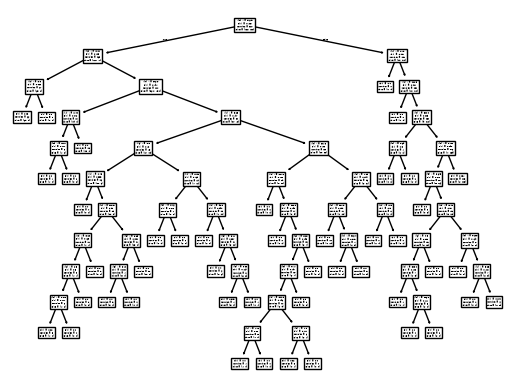

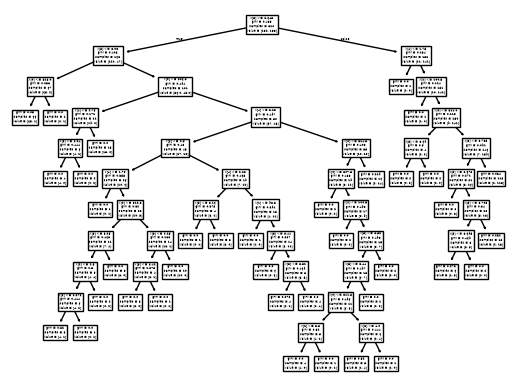

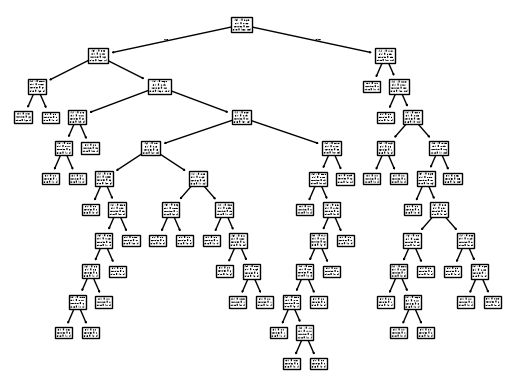

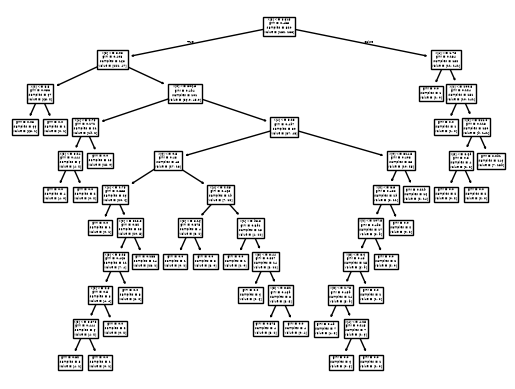

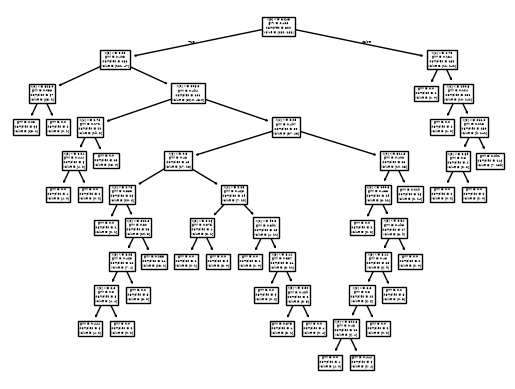

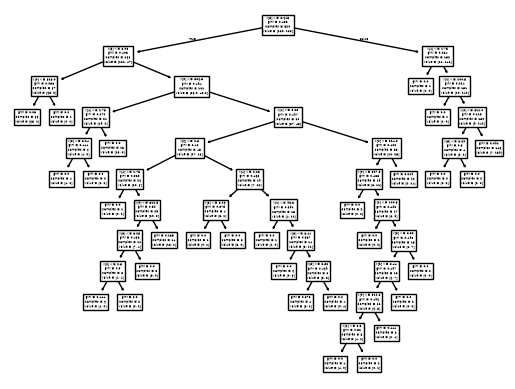

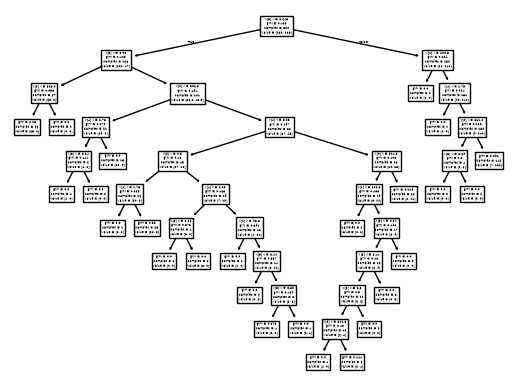

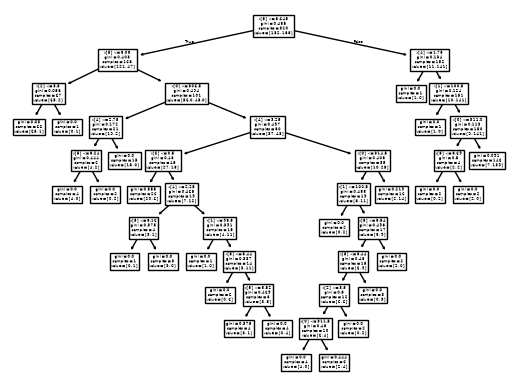

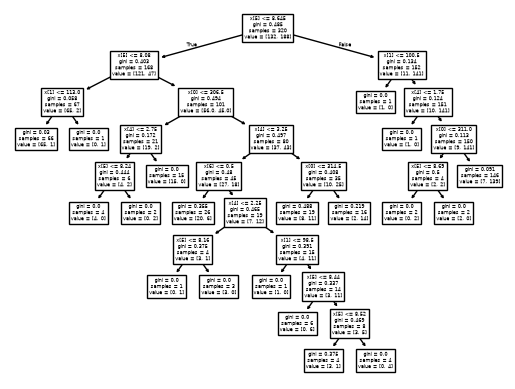

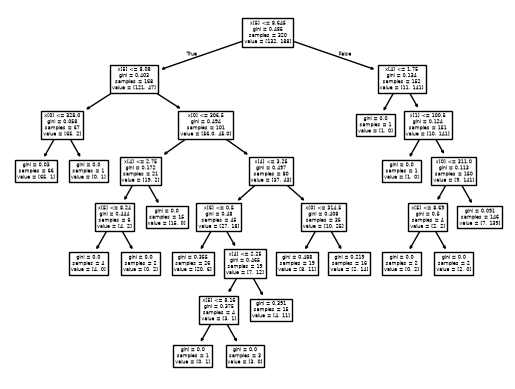

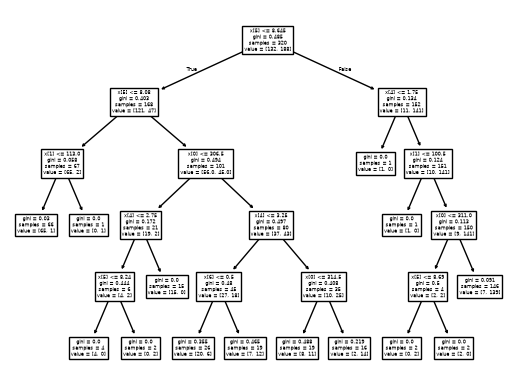

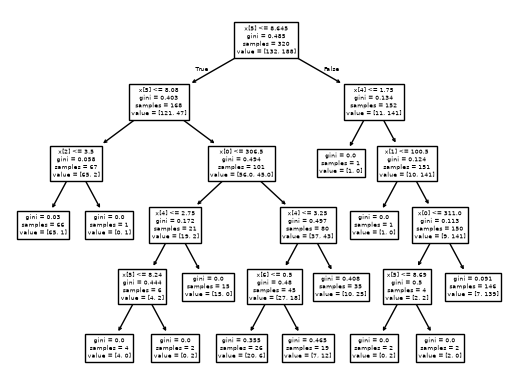

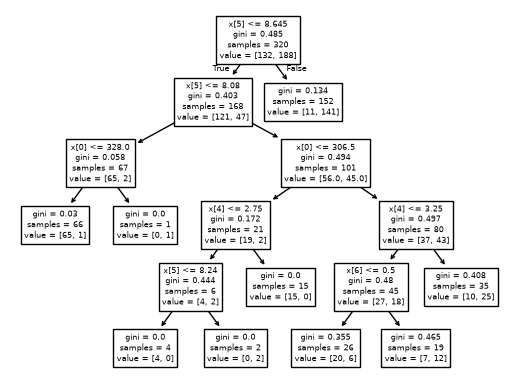

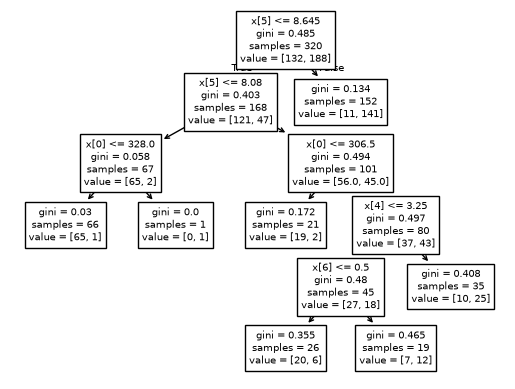

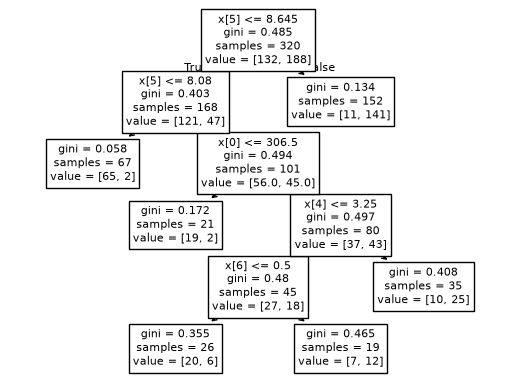

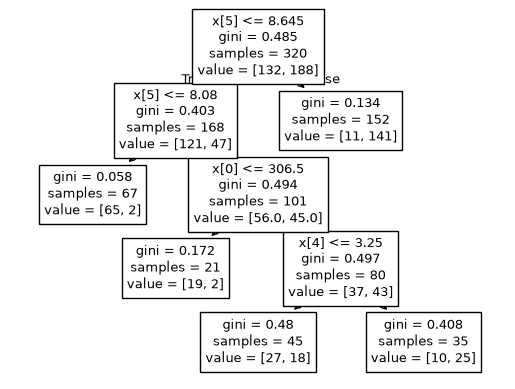

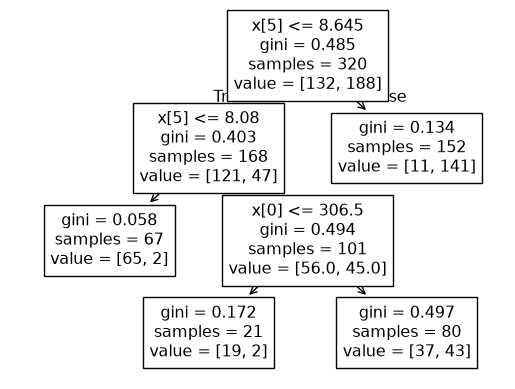

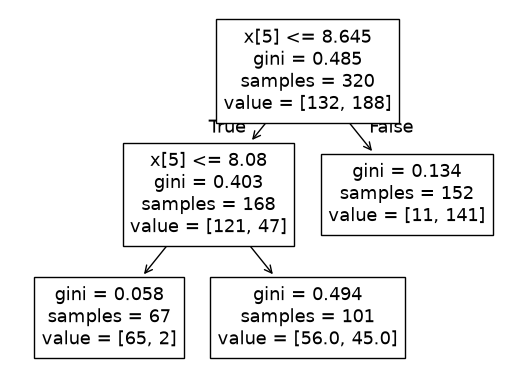

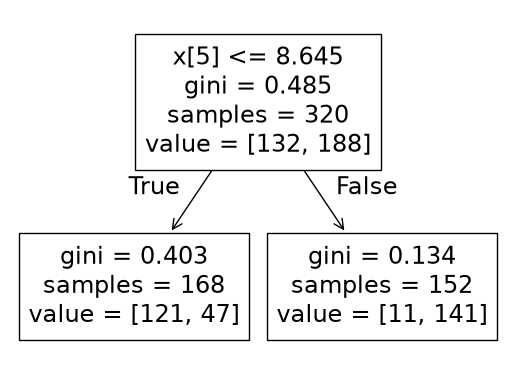

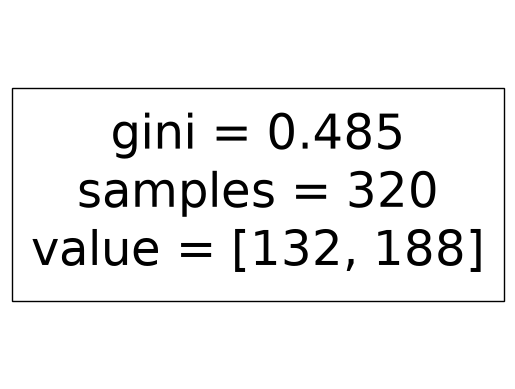

In [71]:
train_acc=[]
test_acc=[]

for i in ccp_alpha['ccp_alphas']:
    dt_model=DecisionTreeClassifier(ccp_alpha=i).fit(xtrain,ytrain)
    train_pred=dt_model.predict(xtrain)
    test_pred=dt_model.predict(xtest)
    train_acc.append(accuracy_score(ytrain,train_pred))
    test_acc.append(accuracy_score(ytest,test_pred))
    plot_tree(dt_model)
    plt.show()

In [75]:
max_df1=pd.DataFrame()
max_df1['ccp_alpha']=ccp_alpha['ccp_alphas']
max_df1['train_accuracy']=train_acc
max_df1['test_accuracy']=test_acc

In [76]:
max_df1['generalzation_gap']=max_df1['train_accuracy']-max_df1['test_accuracy']
max_df1.sort_values(by = 'generalzation_gap',ascending=True)  #ccp- 0.2 has  0 generalizaation gap but accuracy is underfit. so ccp-0.01 has high accuracy

,ccp_alpha,train_accuracy,test_accuracy,generalzation_gap
26,0.209343,0.587500,0.5875,0.000000
22,0.011022,0.865625,0.8375,0.028125
25,0.043502,0.818750,0.7875,0.031250
24,0.020334,0.818750,0.7875,0.031250
21,0.005972,0.881250,0.8375,0.043750
20,0.005655,0.884375,0.8375,0.046875
23,0.012154,0.837500,0.7875,0.050000
19,0.005531,0.890625,0.8375,0.053125
17,0.004649,0.903125,0.8375,0.065625
16,0.004549,0.912500,0.8375,0.075000


In [77]:
# so the final model is ccp_alpha=0.012154

In [78]:
# parameter Tuning  with GridSearchCV
parameters ={
    'criterion':['gini','entropy'],
    'max_depth':[1,2,3,4,5,6,7,8,9,10,11,12,13,14],
    'min_samples_split':[1,2,3,4],
    'min_samples_leaf':[1,2,3]
}


In [81]:
grid_model=DecisionTreeClassifier()

gridsearch=GridSearchCV(grid_model,param_grid=parameters,cv=5,n_jobs=-1)

In [82]:
gridsearch.fit(xtrain,ytrain)

C:\Users\hp\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
420 fits failed out of a total of 1680.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
420 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\hp\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\hp\anaconda3\Lib\site-packages\sklearn\base.py", line 1393, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\hp\anaconda3\Lib\site-packages\sklearn\base.py", line 554, in _validate_params
    validate

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [1, 2, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [1, 2, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose 

In [83]:
gridsearch.best_estimator_

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample